# Phase 03: Model Training, Evaluation & Tuning
Trains and compares baseline classifiers, optimizes hyperparameters via 5-fold stratified cross-validation, and evaluates final generalization performance on the test set.

## 1. Imports & Environment Setup
Configure paths, suppress runtime warnings, and import modeling algorithms, evaluation metrics, and preprocessing utilities.

In [1]:
import sys
sys.path.append("..")

In [2]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")
warnings.showwarning = lambda *args, **kwargs: None

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.preprocess import preprocess

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

## 2. Load Raw Dataset
Load the raw student mental health dataset from the project repository.

In [4]:
root = Path.cwd().parent
DATA_PATH = root / "data" / "origine" / "student_mental_health.csv"
df = pd.read_csv(DATA_PATH)

## 3. Preprocessing & Partitioning
Apply data cleaning, feature engineering, stratified 80/20 train-test splitting, and assemble the modular ColumnTransformer.

In [5]:
X_train, X_test, y_train, y_test, preprocessor = preprocess(df)

## 4. Baseline Model Definition
Initialize baseline candidate classifiers: Logistic Regression, Random Forest, and Support Vector Machine (SVM).

In [6]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
    ),

    "SVM": SVC()
}

## 5. Cross-Validation Configuration
Configure 5-fold stratified cross-validation and define macro-averaged evaluation metrics.

In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}


## 6. Baseline Performance Evaluation
Evaluate baseline models inside leak-free pipelines using 5-fold stratified cross-validation.

In [8]:
results = []

for model_name, model in models.items():

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.751875,0.751980,0.751331,0.750954
1,SVM,0.715625,0.719390,0.715340,0.716440
2,Random Forest,0.681250,0.675685,0.680239,0.676758


## 7. Hyperparameter Search Spaces
Define candidate hyperparameter grids covering regularization, kernel types, class weights, and tree depths.

In [9]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__penalty": ["l1", "l2"],
        "classifier__solver": ["saga"],
        "classifier__class_weight": [
            None,
            "balanced",
            # High = Low = 1
            {"High": 1.0, "Low": 1.0, "Medium": 1.1},
            {"High": 1.0, "Low": 1.0, "Medium": 1.2},
            {"High": 1.0, "Low": 1.0, "Medium": 1.3},
            {"High": 1.0, "Low": 1.0, "Medium": 1.4},
            {"High": 1.0, "Low": 1.0, "Medium": 1.5},
            {"High": 1.0, "Low": 1.0, "Medium": 1.7},
            {"High": 1.0, "Low": 1.0, "Medium": 2.0},
            {"High": 1.0, "Low": 1.0, "Medium": 2.5},
            # High = Low = 0.8
            {"High": 0.8, "Low": 0.8, "Medium": 1.0},
            {"High": 0.8, "Low": 0.8, "Medium": 1.2},
            {"High": 0.8, "Low": 0.8, "Medium": 1.3},
            {"High": 0.8, "Low": 0.8, "Medium": 1.4},
            {"High": 0.8, "Low": 0.8, "Medium": 1.5},
            {"High": 0.8, "Low": 0.8, "Medium": 1.7},
            {"High": 0.8, "Low": 0.8, "Medium": 2.0},
            # High = Low = 0.6
            {"High": 0.6, "Low": 0.6, "Medium": 1.0},
            {"High": 0.6, "Low": 0.6, "Medium": 1.2},
            {"High": 0.6, "Low": 0.6, "Medium": 1.4},
            {"High": 0.6, "Low": 0.6, "Medium": 1.6},
            {"High": 0.6, "Low": 0.6, "Medium": 1.8},
            {"High": 0.6, "Low": 0.6, "Medium": 2.0},
            # High = Low = 1.2
            {"High": 1.2, "Low": 1.2, "Medium": 1.0},
            {"High": 1.2, "Low": 1.2, "Medium": 1.4},
            {"High": 1.2, "Low": 1.2, "Medium": 1.6},
            {"High": 1.2, "Low": 1.2, "Medium": 1.8},
            {"High": 1.2, "Low": 1.2, "Medium": 2.0},
        ],
        "classifier__max_iter": [1000, 2000],
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", "auto", 0.01, 0.1, 1],
        "classifier__kernel": ["linear", "poly", "rbf", "sigmoid"],
        "classifier__class_weight": [
            None,
            "balanced",
            # High = Low = 1
            {"High": 1.0, "Low": 1.0, "Medium": 1.1},
            {"High": 1.0, "Low": 1.0, "Medium": 1.2},
            {"High": 1.0, "Low": 1.0, "Medium": 1.3},
            {"High": 1.0, "Low": 1.0, "Medium": 1.4},
            {"High": 1.0, "Low": 1.0, "Medium": 1.5},
            {"High": 1.0, "Low": 1.0, "Medium": 1.7},
            {"High": 1.0, "Low": 1.0, "Medium": 2.0},
            {"High": 1.0, "Low": 1.0, "Medium": 2.5},
            # High = Low = 0.8
            {"High": 0.8, "Low": 0.8, "Medium": 1.0},
            {"High": 0.8, "Low": 0.8, "Medium": 1.2},
            {"High": 0.8, "Low": 0.8, "Medium": 1.3},
            {"High": 0.8, "Low": 0.8, "Medium": 1.4},
            {"High": 0.8, "Low": 0.8, "Medium": 1.5},
            {"High": 0.8, "Low": 0.8, "Medium": 1.7},
            {"High": 0.8, "Low": 0.8, "Medium": 2.0},
            # High = Low = 0.6
            {"High": 0.6, "Low": 0.6, "Medium": 1.0},
            {"High": 0.6, "Low": 0.6, "Medium": 1.2},
            {"High": 0.6, "Low": 0.6, "Medium": 1.4},
            {"High": 0.6, "Low": 0.6, "Medium": 1.6},
            {"High": 0.6, "Low": 0.6, "Medium": 1.8},
            {"High": 0.6, "Low": 0.6, "Medium": 2.0},
            # High = Low = 1.2
            {"High": 1.2, "Low": 1.2, "Medium": 1.0},
            {"High": 1.2, "Low": 1.2, "Medium": 1.4},
            {"High": 1.2, "Low": 1.2, "Medium": 1.6},
            {"High": 1.2, "Low": 1.2, "Medium": 1.8},
            {"High": 1.2, "Low": 1.2, "Medium": 2.0},
        ],
    },
    "Random Forest": {
        "classifier__n_estimators": [50, 100, 200, 300],
        "classifier__max_depth": [5, 10, 15, None],
        "classifier__min_samples_split": [2, 5, 10, 15, 20],
        "classifier__min_samples_leaf": [1, 2, 4, 6, 8, 10],
    },
}

## 8. Hyperparameter Tuning (GridSearchCV)
Optimize hyperparameters across all models using 5-fold CV to maximize macro F1-score.

In [10]:
tuning_results = []
best_models = {}

for model_name, model in models.items():

    print(f"\nTuning {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        cv=cv,
        scoring=scoring,
        refit="f1",
        n_jobs=-1,
        verbose=1,
        return_train_score=False
    )

    grid_search.fit(X_train, y_train)

    best_models[model_name] = grid_search.best_estimator_

    best_index = grid_search.best_index_

    tuning_results.append({
        "Model": model_name,
        "Accuracy": grid_search.cv_results_["mean_test_accuracy"][best_index],
        "Precision": grid_search.cv_results_["mean_test_precision"][best_index],
        "Recall": grid_search.cv_results_["mean_test_recall"][best_index],
        "F1-Score": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)

display(tuning_df)


Tuning Logistic Regression...
Fitting 5 folds for each of 672 candidates, totalling 3360 fits

Tuning Random Forest...
Fitting 5 folds for each of 480 candidates, totalling 2400 fits

Tuning SVM...
Fitting 5 folds for each of 2240 candidates, totalling 11200 fits


,Model,Accuracy,Precision,Recall,F1-Score,Best Parameters
0,Logistic Regression,0.755000,0.762573,0.754737,0.757130,"{'classifier__C': 1, 'classifier__class_weight': {'High': 1.2, 'Low': 1.2, 'Medium': 1.4}, 'classifier__max_iter': 1000, 'classifier__penalty': 'l1', 'classifier__solver': 'saga'}"
1,SVM,0.746250,0.755716,0.746180,0.748932,"{'classifier__C': 0.1, 'classifier__class_weight': {'High': 1.0, 'Low': 1.0, 'Medium': 1.1}, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}"
2,Random Forest,0.693125,0.688890,0.692266,0.689394,"{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}"


## 9. Final Test Set Evaluation & Confusion Matrices
Evaluate the best-tuned models on the unseen test set ($N = 400$) and generate classification reports and confusion matrices.

Logistic Regression Report :


,High,Low,Medium,accuracy,macro avg,weighted avg
precision,0.846154,0.848000,0.648276,0.775,0.780810,0.781463
recall,0.808824,0.803030,0.712121,0.775,0.774658,0.775000
f1-score,0.827068,0.824903,0.678700,0.775,0.776890,0.777392
support,136.000000,132.000000,132.000000,0.775,400.000000,400.000000


Random Forest Report :


,High,Low,Medium,accuracy,macro avg,weighted avg
precision,0.750000,0.772059,0.572581,0.7025,0.698213,0.698731
recall,0.772059,0.795455,0.537879,0.7025,0.701797,0.702500
f1-score,0.760870,0.783582,0.554688,0.7025,0.699713,0.700325
support,136.000000,132.000000,132.000000,0.7025,400.000000,400.000000


SVM Report :


,High,Low,Medium,accuracy,macro avg,weighted avg
precision,0.829630,0.838710,0.638298,0.765,0.768879,0.769487
recall,0.823529,0.787879,0.681818,0.765,0.764409,0.765000
f1-score,0.826568,0.812500,0.659341,0.765,0.766136,0.766741
support,136.000000,132.000000,132.000000,0.765,400.000000,400.000000


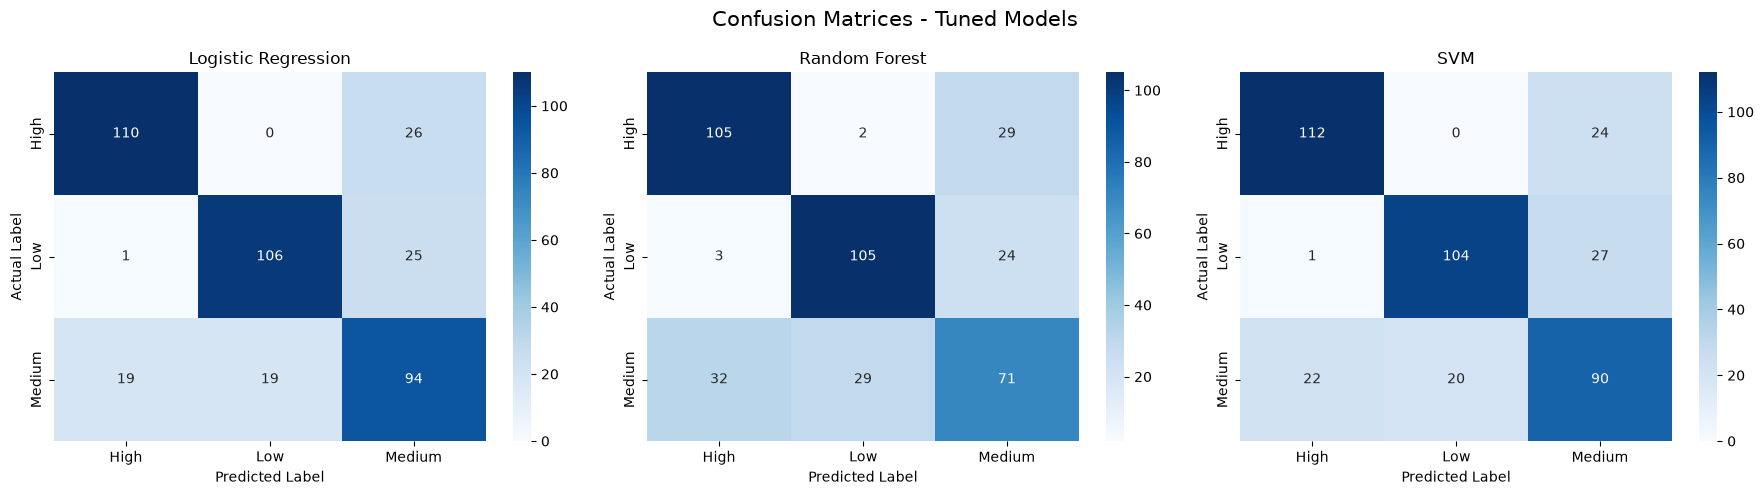

In [11]:
reports = []

fig, axes = plt.subplots(
    1,
    len(best_models),
    figsize=(18, 5)
)

for ax, (model_name, model) in zip(
    axes,
    best_models.items()
):

    y_pred = model.predict(X_test)

    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose().T

    print(f"{model_name} Report :")

    display(report_df)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrices - Tuned Models", fontsize=15)
plt.tight_layout()
plt.show()


## 10. Modeling Summary & Findings
- **Best Performance:** Logistic Regression and SVM achieved the highest test performance (~0.76 macro F1).
- **Class Disparity:** High and Low risk classes exhibit high precision and recall (>0.80), while Medium risk remains the most challenging class to separate.